# Thermochronology data from the Montreal River Monocline

## Import Python packages

In [1]:
import numpy as np
import pandas as pd
import string
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', None)
import matplotlib.pyplot as plt

%matplotlib inline
%config InlineBackend.figure_format='retina'

## Import zircon data from the HAL lab

These data have been processed using data reduction scripts available in the wrguenthner repositories.

In [2]:
# URLs
url_1 = "https://raw.githubusercontent.com/wrguenthner/HAL_data/main/projects_2023/TA23_MRM_MCR/TA23_MRM_MCR_1_report.csv"
url_2 = "https://raw.githubusercontent.com/wrguenthner/HAL_data/main/projects_2023/TA23_MRM_MCR/TA23_MRM_MCR_2_report.csv"
url_3 = "https://raw.githubusercontent.com/wrguenthner/HAL_data/main/projects_2023/TA23_MRM_MCR/TA23_MRM_MCR_3_report.csv"
url_4 = "https://raw.githubusercontent.com/wrguenthner/HAL_data/main/projects_2023/TA23_MRM_MCR/TA23_MRM_MCR_4_report.csv"
url_5 = "https://raw.githubusercontent.com/wrguenthner/HAL_data/main/projects_2023/TA23_MRM_MCR/TA23_MRM_MCR_5_report.csv"

# Read data
data_1 = pd.read_csv(url_1)
data_2 = pd.read_csv(url_2)
data_3_disc2 = pd.read_csv(url_3)
data_4_disc3 = pd.read_csv(url_4)
data_5_disc4 = pd.read_csv(url_5)

# Add a new column 'source_url' to each DataFrame
data_1['source_url'] = url_1
data_2['source_url'] = url_2
data_3_disc2['source_url'] = url_3
data_4_disc3['source_url'] = url_4
data_5_disc4['source_url'] = url_5

# Concatenate the DataFrames
data_disc1_2_3_4 = pd.concat([data_1, data_2, data_3_disc2, data_4_disc3, data_5_disc4])
data_disc1_2_3_4 = data_disc1_2_3_4[data_disc1_2_3_4['analysis_notes']!='Empty']
data_disc1_2_3_4.reset_index(inplace=True)
data_disc1_2_3_4.to_csv("../data/UTh_He_zircon_data.csv", index=False)

data_disc1_2_3_4.head()

,index,Unnamed: 0,analysis_notes,morph_notes,corrected_date,corrected_1s,corrected_1s_%,radius,Ft,uncorrected_date,...,Sm_ng_1s_%,He_pmol,He_pmol_1s,He_pmol_1s_%,mass_morph_g,U_ppm,Th_ppm,Sm_ppm,eU,source_url
0,0,TAI_FCT_z1,NaN,NaN,23.509002,0.846014,3.598680,89.173068,0.850626,20.003763,...,0,0.037058,0.001143,3.085638,0.000025,7.758218,26.314767,0.0,13.942188,https://raw.githubusercontent.com/wrguenthner/HAL_data/main/projects_2023/TA23_MRM_MCR/TA23_MRM_MCR_1_report.csv
1,1,TAI_MRM1_z1,NaN,mod,873.220826,13.957786,1.598426,36.350348,0.671065,601.079624,...,0,1.320565,0.005403,0.409115,0.000001,227.768724,127.097946,0.0,257.636741,https://raw.githubusercontent.com/wrguenthner/HAL_data/main/projects_2023/TA23_MRM_MCR/TA23_MRM_MCR_1_report.csv
2,2,TAI_MRM1_z2,NaN,low eu,719.495431,16.216051,2.253809,35.669719,0.667156,490.431492,...,0,1.127645,0.004634,0.410981,0.000001,279.730221,100.422081,0.0,303.329410,https://raw.githubusercontent.com/wrguenthner/HAL_data/main/projects_2023/TA23_MRM_MCR/TA23_MRM_MCR_1_report.csv
3,3,TAI_MRM1_z3,NaN,low eu,831.002111,13.083478,1.574422,46.053177,0.734087,621.976075,...,0,1.951537,0.007961,0.407947,0.000003,174.803634,107.683401,0.0,200.109233,https://raw.githubusercontent.com/wrguenthner/HAL_data/main/projects_2023/TA23_MRM_MCR/TA23_MRM_MCR_1_report.csv
4,4,TAI_MRM2_z1,NaN,mod-high eu,694.772371,10.216665,1.470505,47.530903,0.744185,525.437954,...,0,7.594291,0.030923,0.407192,0.000004,556.570665,140.559155,0.0,589.602066,https://raw.githubusercontent.com/wrguenthner/HAL_data/main/projects_2023/TA23_MRM_MCR/TA23_MRM_MCR_1_report.csv


In [3]:
data_4_disc3

,Unnamed: 0,analysis_notes,morph_notes,corrected_date,corrected_1s,corrected_1s_%,radius,Ft,uncorrected_date,uncorrected_1s,...,Sm_ng_1s_%,He_pmol,He_pmol_1s,He_pmol_1s_%,mass_morph_g,U_ppm,Th_ppm,Sm_ppm,eU,source_url
0,TAI_FCT_z7,NaN,NaN,25.483278,0.489458,1.920703,55.771627,0.777705,19.828925,0.378709,...,0,0.441717,0.001846,0.417940,6.480183e-06,5.655819e+02,301.367569,0.0,6.364033e+02,https://raw.githubusercontent.com/wrguenthner/HAL_data/main/projects_2023/TA23_MRM_MCR/TA23_MRM_MCR_4_report.csv
1,NSVG_DKR1_z5,NaN,low-mod eu,1020.878227,21.512676,2.107271,38.329706,0.685149,719.503581,14.667851,...,0,1.188465,0.004516,0.380003,2.268964e-06,1.084461e+02,77.556302,0.0,1.266719e+02,https://raw.githubusercontent.com/wrguenthner/HAL_data/main/projects_2023/TA23_MRM_MCR/TA23_MRM_MCR_4_report.csv
2,NSVG_DKR1_z6,NaN,low eu,947.215388,33.376172,3.523610,27.957904,0.582819,571.013683,19.324405,...,0,0.286656,0.001401,0.488566,7.331940e-07,9.901136e+01,93.189007,0.0,1.209108e+02,https://raw.githubusercontent.com/wrguenthner/HAL_data/main/projects_2023/TA23_MRM_MCR/TA23_MRM_MCR_4_report.csv
3,NSVG_DKR1_z7,NaN,low eu,999.181269,21.738094,2.175591,28.717798,0.592444,613.039475,13.060283,...,0,0.397506,0.001641,0.412898,7.575191e-07,1.238059e+02,113.938704,0.0,1.505815e+02,https://raw.githubusercontent.com/wrguenthner/HAL_data/main/projects_2023/TA23_MRM_MCR/TA23_MRM_MCR_4_report.csv
4,NSVG_DKR1_z8,NaN,low eu,947.121529,34.683975,3.662041,26.683139,0.566172,555.444458,19.744019,...,0,0.165625,0.000876,0.528641,5.641198e-07,7.691195e+01,70.416513,0.0,9.345983e+01,https://raw.githubusercontent.com/wrguenthner/HAL_data/main/projects_2023/TA23_MRM_MCR/TA23_MRM_MCR_4_report.csv
5,TA_MRM7_z4,NaN,mod-high eu,109.681747,1.898859,1.731244,64.228391,0.805795,88.546118,1.524385,...,0,3.338896,0.012512,0.374741,8.731963e-06,7.218859e+02,310.217869,0.0,7.947871e+02,https://raw.githubusercontent.com/wrguenthner/HAL_data/main/projects_2023/TA23_MRM_MCR/TA23_MRM_MCR_4_report.csv
6,TA_MRM7_z5,NaN,high eu,197.872804,2.680164,1.354489,76.969028,0.831853,165.027266,2.224726,...,0,12.474469,0.046675,0.374163,1.511040e-05,6.544555e+02,1107.094242,0.0,9.146226e+02,https://raw.githubusercontent.com/wrguenthner/HAL_data/main/projects_2023/TA23_MRM_MCR/TA23_MRM_MCR_4_report.csv
7,TA_MRM9_z5,NaN,low eu,951.663664,15.950631,1.676079,62.774369,0.800722,774.951341,12.715398,...,0,10.098966,0.037777,0.374071,9.377614e-06,2.110909e+02,124.334136,0.0,2.403094e+02,https://raw.githubusercontent.com/wrguenthner/HAL_data/main/projects_2023/TA23_MRM_MCR/TA23_MRM_MCR_4_report.csv
8,TAI_FCT_z8,NaN,NaN,25.390786,0.528144,2.080060,53.484850,0.768524,19.524162,0.403555,...,0,0.194434,0.000786,0.403994,5.431262e-06,2.979906e+02,176.308814,0.0,3.394231e+02,https://raw.githubusercontent.com/wrguenthner/HAL_data/main/projects_2023/TA23_MRM_MCR/TA23_MRM_MCR_4_report.csv
9,TA_MRM20_z1,NaN,mod-high eu,585.243508,10.370051,1.771921,58.150508,0.787914,466.315349,8.144466,...,0,5.880119,0.012208,0.207622,5.577898e-06,3.797733e+02,93.408182,0.0,4.017242e+02,https://raw.githubusercontent.com/wrguenthner/HAL_data/main/projects_2023/TA23_MRM_MCR/TA23_MRM_MCR_4_report.csv


Here we filter out (based on reccomendation from Wily and our intuition):

- analysis 'TA_MRM20_z3' (where the eU is also 2.3e6)
- TAI_MA5_z1
- TAI_MA5_z2
- TAI_MRM34_z21
- TAI_MRM34_z22
- TAI_MRM34_z23

In [4]:
data_disc1_2_3_4 = data_disc1_2_3_4[data_disc1_2_3_4['Unnamed: 0']!='TA_MRM20_z3']
data_disc1_2_3_4 = data_disc1_2_3_4[data_disc1_2_3_4['Unnamed: 0']!='TAI_MA5_z1']
data_disc1_2_3_4 = data_disc1_2_3_4[data_disc1_2_3_4['Unnamed: 0']!='TAI_MA5_z2']
data_disc1_2_3_4 = data_disc1_2_3_4[data_disc1_2_3_4['Unnamed: 0']!='TAI_MRM34_z21']
data_disc1_2_3_4 = data_disc1_2_3_4[data_disc1_2_3_4['Unnamed: 0']!='TAI_MRM34_z22']
data_disc1_2_3_4 = data_disc1_2_3_4[data_disc1_2_3_4['Unnamed: 0']!='TAI_MRM34_z23']

In [5]:
# Split the 'Unnamed: 0' column which has the analysis name into three parts
splits = data_disc1_2_3_4['Unnamed: 0'].str.split('_', expand=True)

# Assign the second part (index 1) to the new 'sample' column
data_disc1_2_3_4['sample'] = splits[1]

# Assign the third part (index 2) to the new 'grain' column
data_disc1_2_3_4['grain'] = splits[2]

There are some grains that have different "TAI" and "TA" prefixes, but everything else is the same. The next bit of code finds the "duplicates" and gives them unique grain names.

In [ ]:
# Combine sample + grain to detect duplicates
combo = data_disc1_2_3_4['sample'] + '_' + data_disc1_2_3_4['grain']

# True for the second occurrence of a repeated sample/grain combo
is_dup = combo.duplicated(keep='first')

# Prefix digit for duplicates: '1' by default, '2' for sample MRM34
suffix = pd.Series('1', index=data_disc1_2_3_4.index)
suffix[data_disc1_2_3_4['sample'] == 'MRM34'] = '2'

# Split duplicate grains into letters + number (e.g. "z1" -> "z", "1")
parts = data_disc1_2_3_4.loc[is_dup, 'grain'].str.extract(r'^([^\d]*)(\d+)$')

# Insert the digit between the letters and the number: "z1" -> "z11" / "z21"
data_disc1_2_3_4.loc[is_dup, 'grain'] = parts[0] + suffix[is_dup] + parts[1]


In [7]:
MRM_Archean_samples = ['MRM1','MRM2','MRM4','MRM5','MRM6','MRM35','MRM20',
                       'MRM8','MRM17','MRM16','MRM7','MRM21', 'MRM36']

Other_Archean_samples = ['MRM24']
 
MRM_rift_samples = ['MRM9', 'MRM34', 'MC4']

MRM_Freda_samples = ['LRA','BRB']

MRM_Archean_data = data_disc1_2_3_4[data_disc1_2_3_4['sample'].isin(MRM_Archean_samples)]
Other_Archean_data = data_disc1_2_3_4[data_disc1_2_3_4['sample'].isin(Other_Archean_samples)]
MRM_rift_data = data_disc1_2_3_4[data_disc1_2_3_4['sample'].isin(MRM_rift_samples)]
MRM_Freda_data = data_disc1_2_3_4[data_disc1_2_3_4['sample'].isin(MRM_Freda_samples)]

In [8]:
def plot_age_eU(data, title, x_max=None, y_max=None, color_by_sample=True, ax=None,
                legend_loc='upper right'):
    # Create a new figure and axes if not provided
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 6))
        own_figure = True
    else:
        own_figure = False

    # Set axis labels and limits
    ax.set_xlabel('eU')
    ax.set_ylabel('Corrected Date')
    if x_max is not None:
        ax.set_xlim(0, x_max)
    if y_max is not None:
        ax.set_ylim(0, y_max)
    ax.set_title(title, fontsize=20, fontweight='bold')

    # Get the default color cycle
    color_cycle = plt.rcParams['axes.prop_cycle'].by_key()['color']
    num_colors = len(color_cycle)

    # Map analysis-name sample codes to full field sample names for legend display
    legend_labels = {'BRB': 'BRb-1.2', 'LRA': 'LRa-67.0'}

    # Plotting logic
    if color_by_sample:
        unique_samples = data['sample'].unique()
        for i, sample_name in enumerate(unique_samples):
            subset = data[data['sample'] == sample_name]
            # Use circles ('o') for the first set of colors, then squares ('s')
            marker = 'o' if i < num_colors else 's'
            color = color_cycle[i % num_colors]
            ax.errorbar(subset['eU'], subset['corrected_date'], yerr=subset['corrected_1s'], fmt=marker, color=color, label=legend_labels.get(sample_name, sample_name), capsize=0, elinewidth=1)
    else:
        ax.errorbar(data['eU'], data['corrected_date'], yerr=data['corrected_1s'], fmt='o', capsize=0, elinewidth=1)

    # Show legend if coloring by sample
    if color_by_sample:
        ax.legend(title='Sample', loc=legend_loc)

    # Show the plot if this function created its own figure
    if own_figure:
        plt.tight_layout()  # Adjust layout to fit everything properly
        plt.show()

    # Return the axes object
    return ax


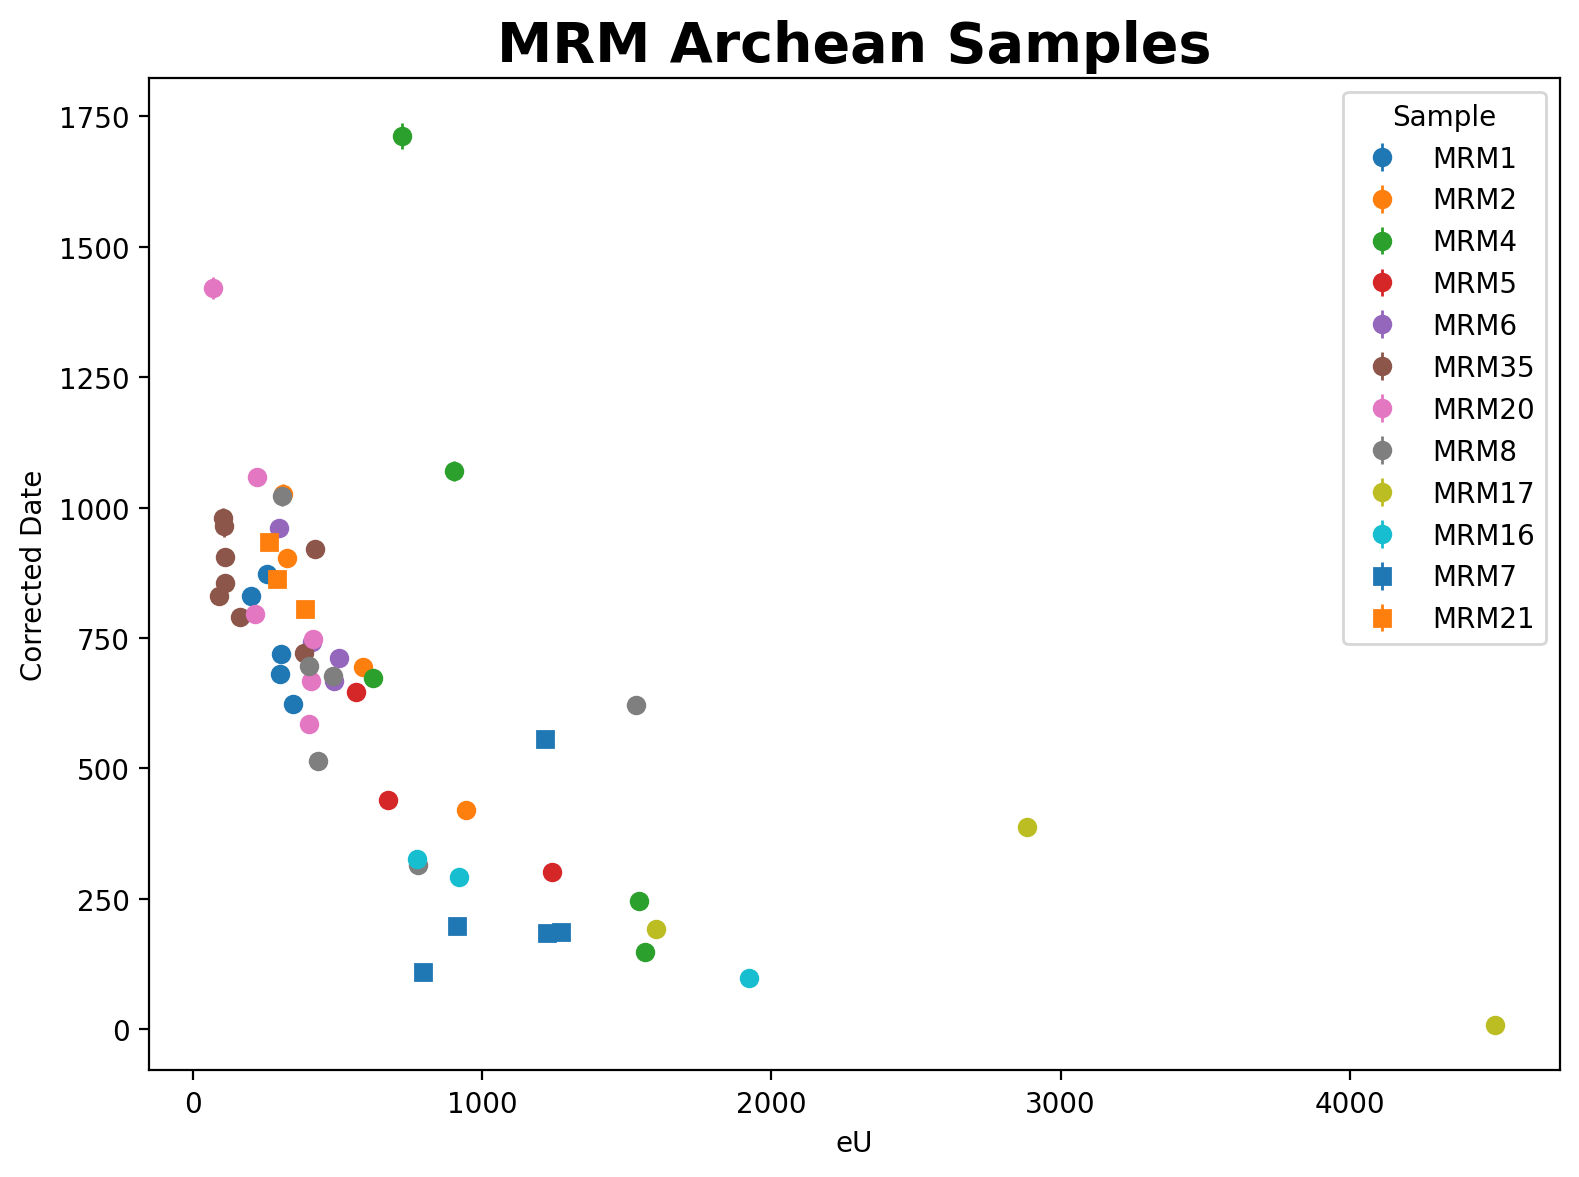

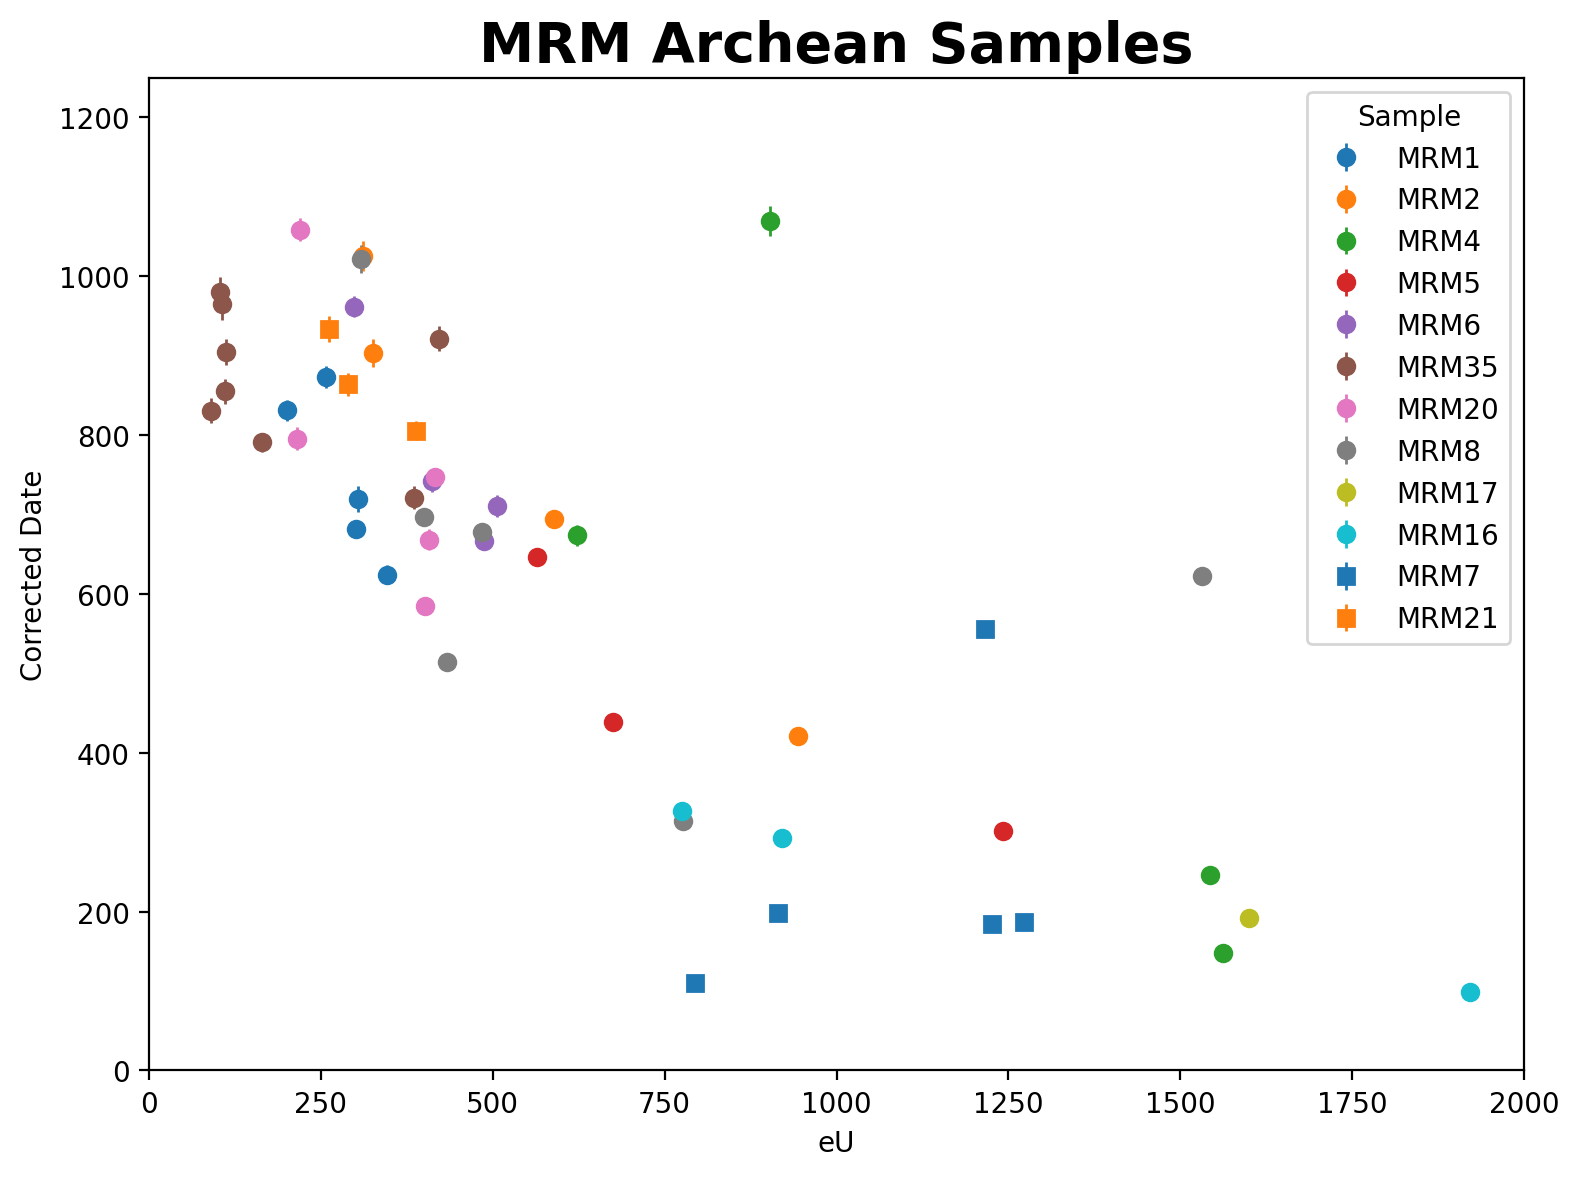

<Axes: title={'center': 'MRM Archean Samples'}, xlabel='eU', ylabel='Corrected Date'>

In [9]:
plot_age_eU(MRM_Archean_data, 'MRM Archean Samples')
plot_age_eU(MRM_Archean_data, 'MRM Archean Samples', x_max= 2000, y_max = 1250)

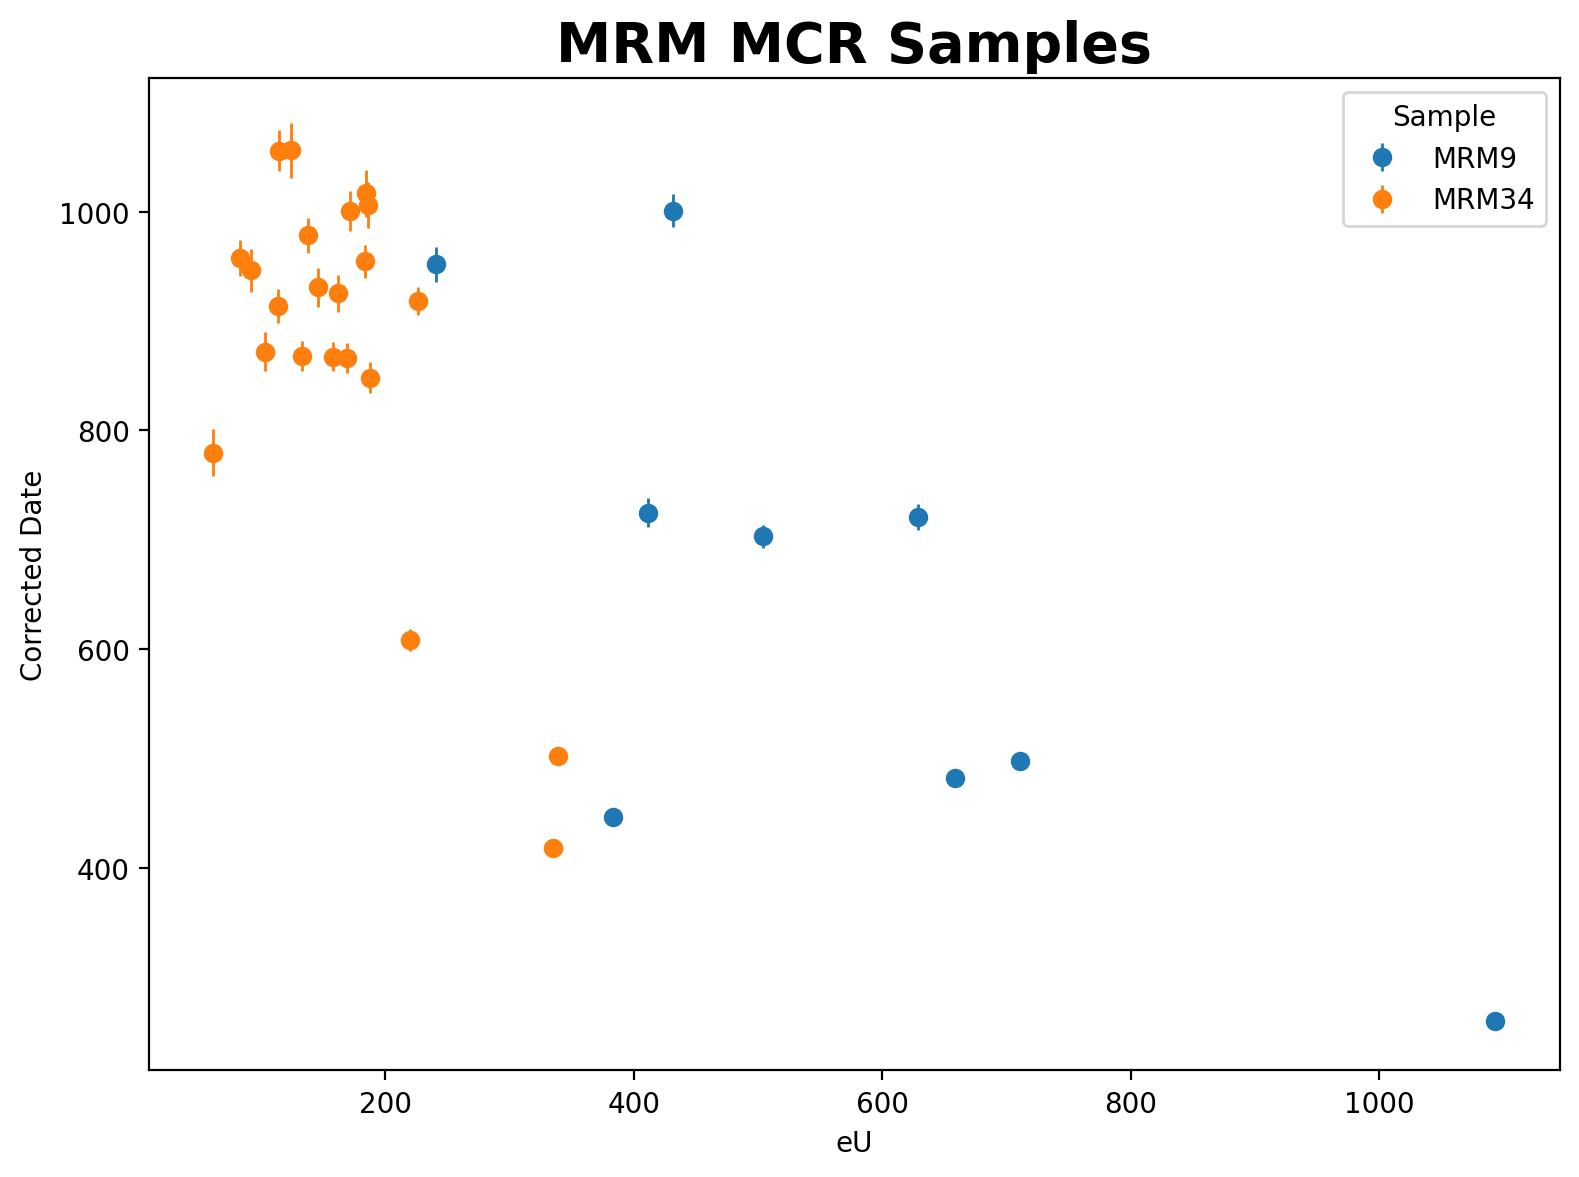

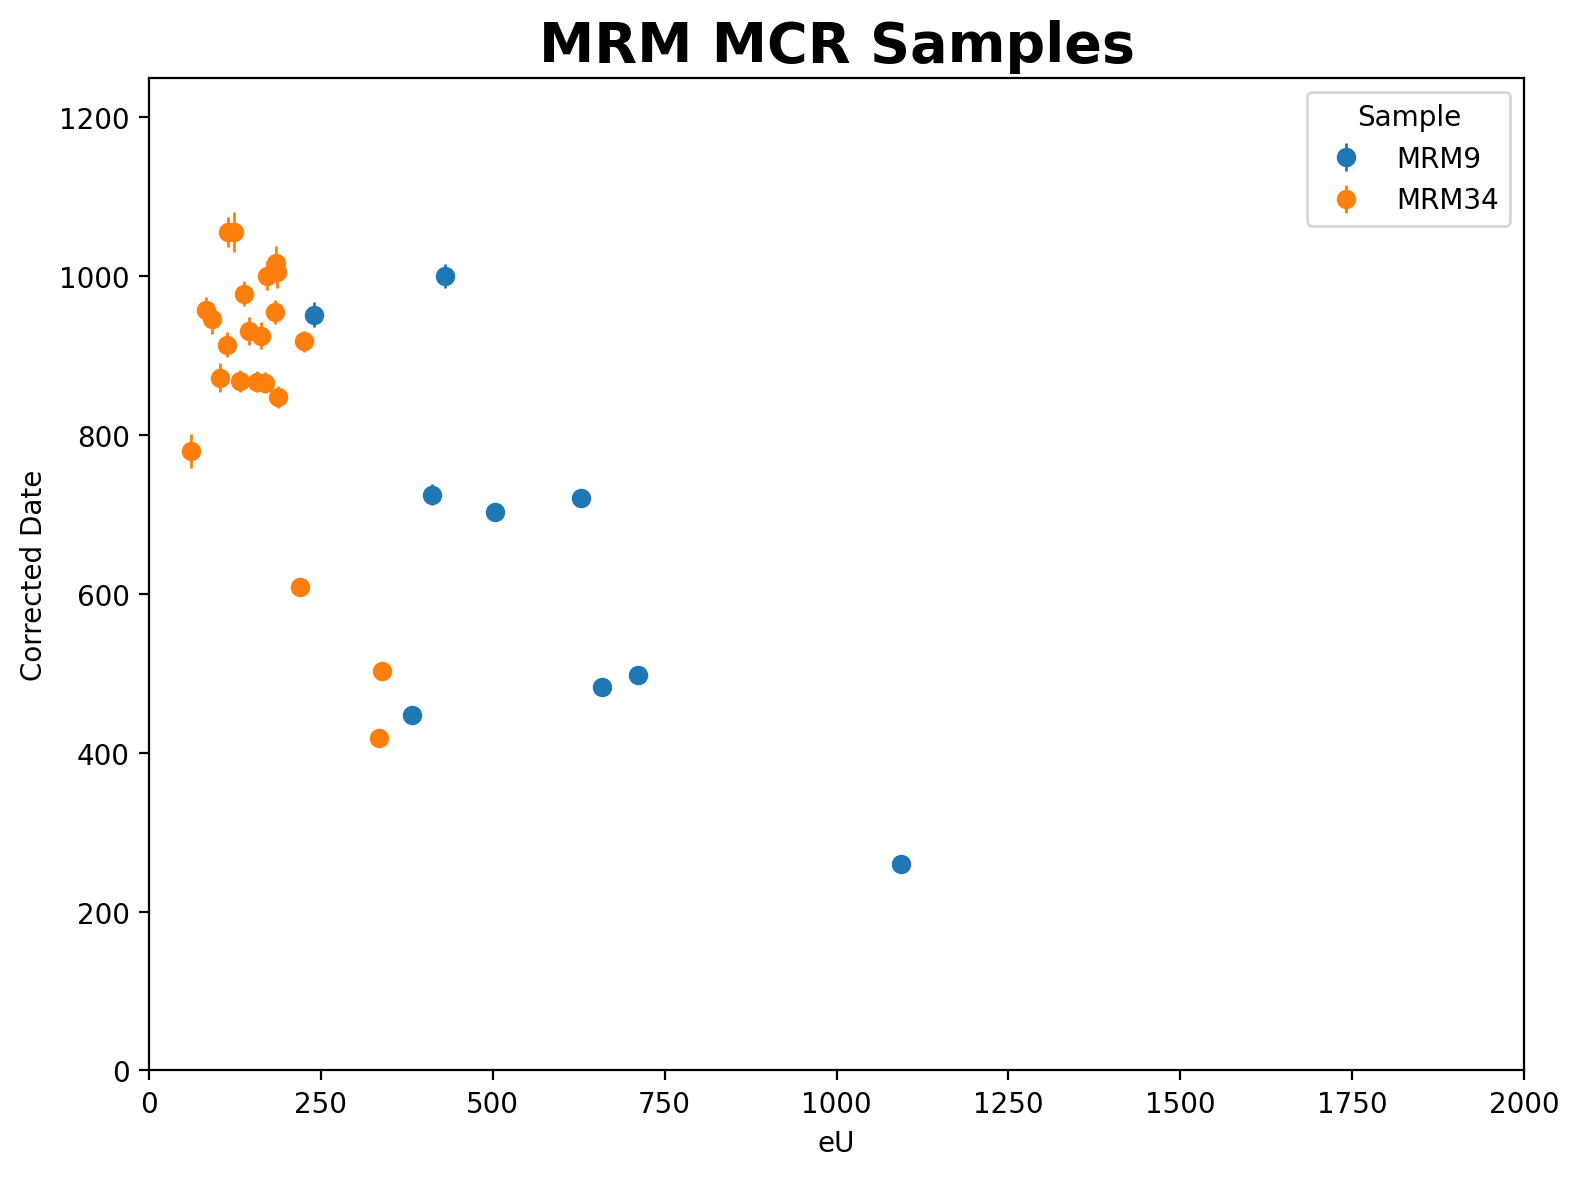

<Axes: title={'center': 'MRM MCR Samples'}, xlabel='eU', ylabel='Corrected Date'>

In [10]:
plot_age_eU(MRM_rift_data, 'MRM MCR Samples')
plot_age_eU(MRM_rift_data, 'MRM MCR Samples', x_max= 2000, y_max = 1250)

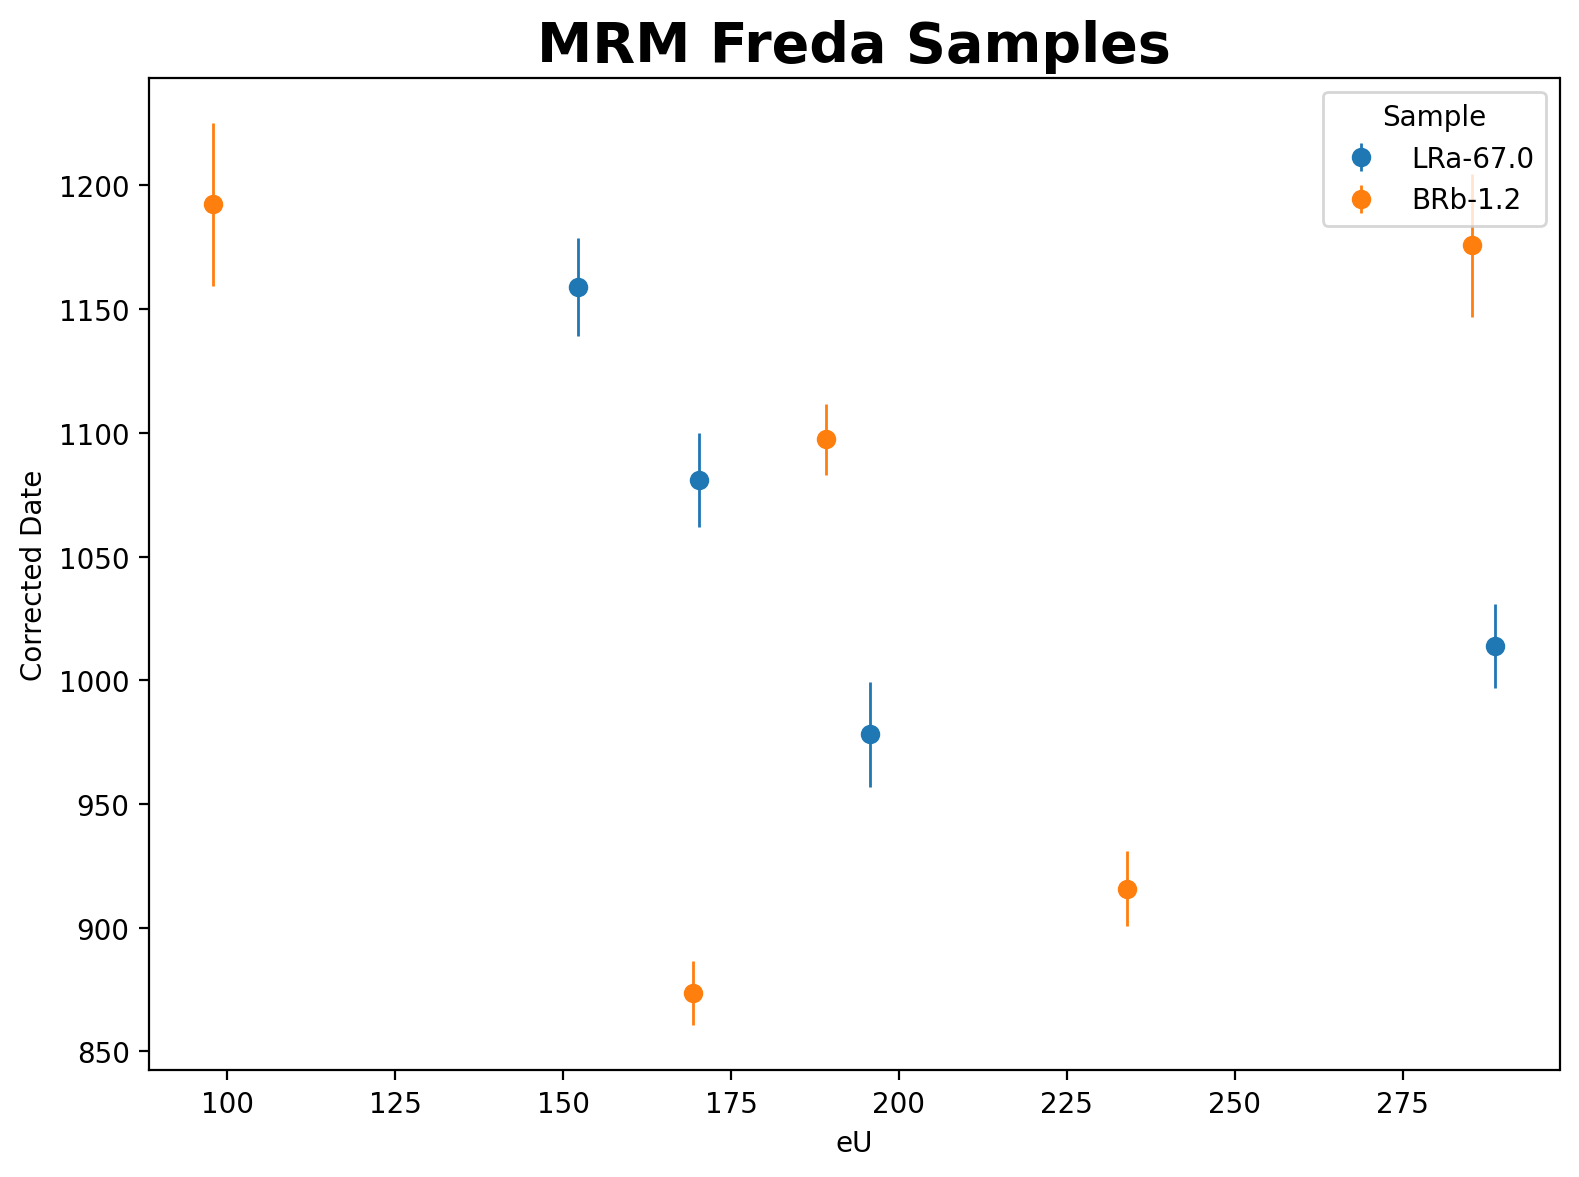

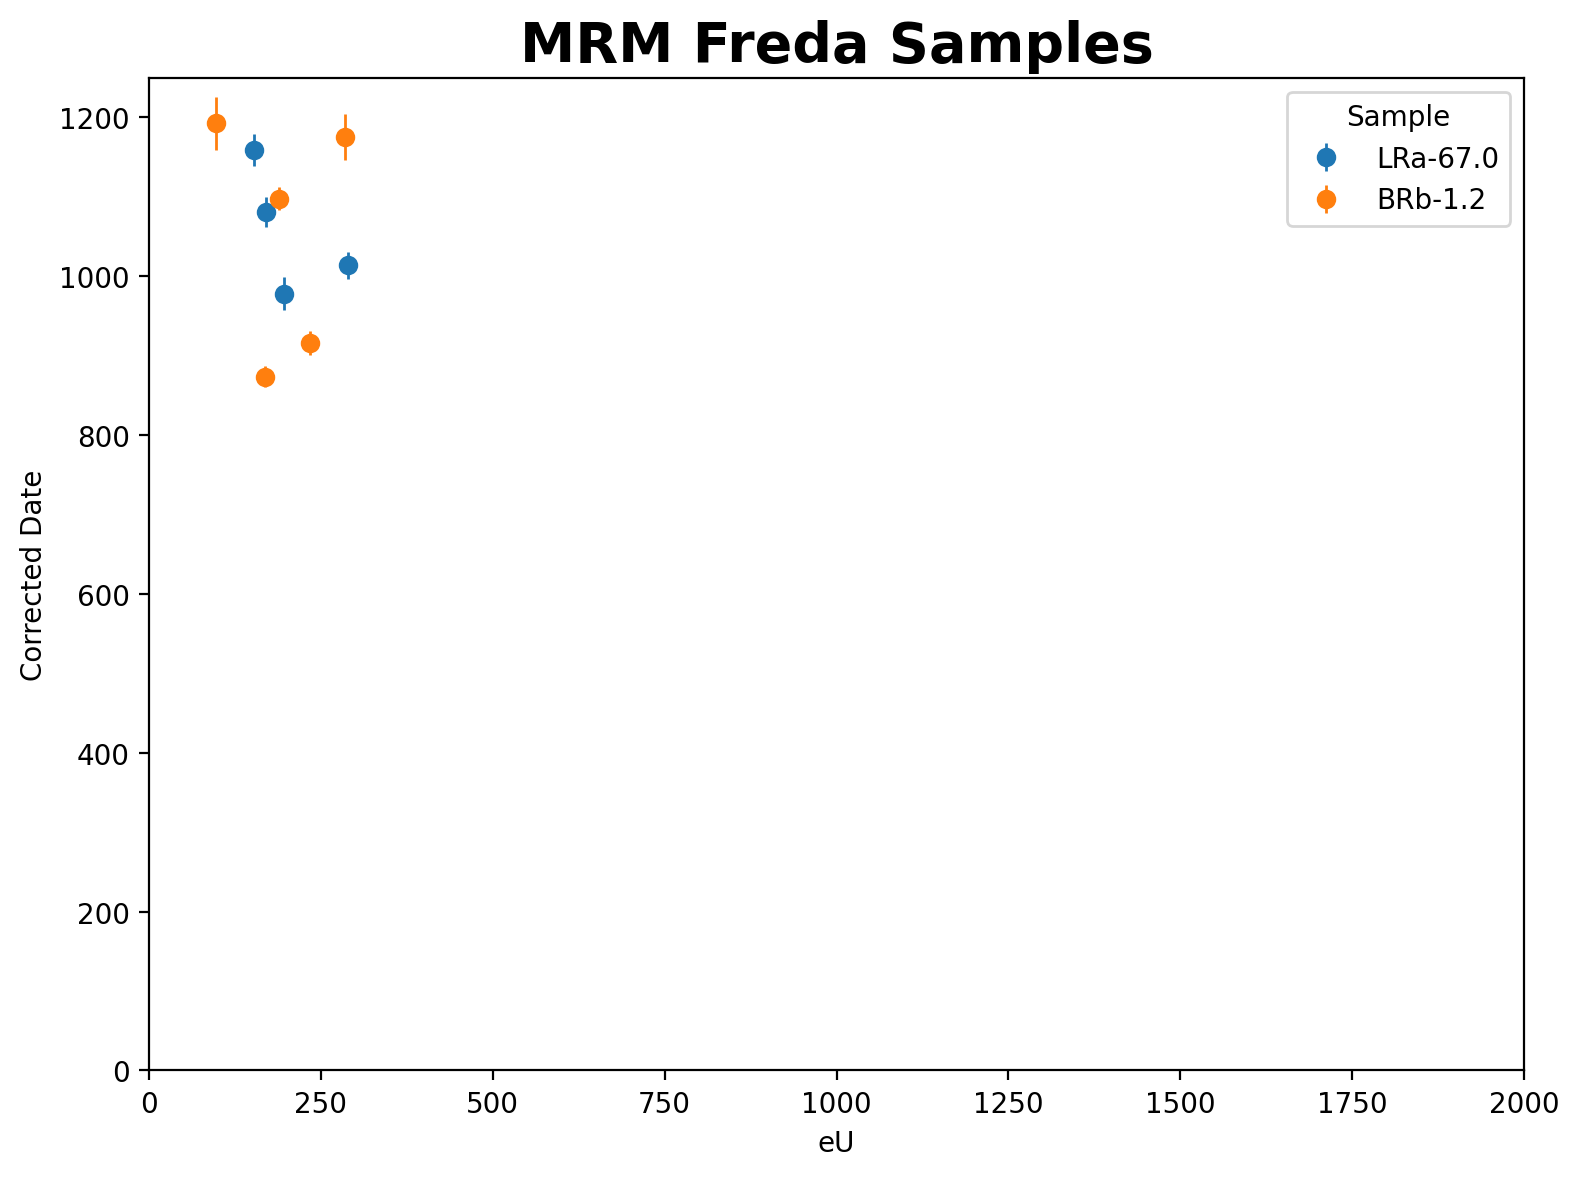

<Axes: title={'center': 'MRM Freda Samples'}, xlabel='eU', ylabel='Corrected Date'>

In [11]:
plot_age_eU(MRM_Freda_data, 'MRM Freda Samples')
plot_age_eU(MRM_Freda_data, 'MRM Freda Samples', x_max= 2000, y_max = 1250)

In [12]:
url = "https://raw.githubusercontent.com/wrguenthner/HAL_data/main/projects_2023/TA23_MRM_MCR/TA23_MRM_MCR_7_report.csv"
data_a_1 = pd.read_csv(url)

url = "https://raw.githubusercontent.com/wrguenthner/HAL_data/main/projects_2023/TA23_MRM_MCR/TA23_MRM_MCR_8_report.csv"
data_a_2 = pd.read_csv(url)

data_a = pd.concat([data_a_1, data_a_2])
data_a = data_a[(data_a['analysis_notes'] != 'Empty') & (data_a['analysis_notes'] != 'empty?')]
data_a.reset_index(inplace=True)

data_a = data_a [data_a ['Unnamed: 0']!='TAI_MG_G1_a2']
data_a = data_a[data_a['Unnamed: 0'] != 'TAI_BRB_a1']
data_a = data_a.drop_duplicates(subset='Unnamed: 0')

# Split the 'Unnamed: 0' column which has the analysis name into three parts
splits = data_a['Unnamed: 0'].str.split('_', expand=True)

# Assign the second part (index 1) to the new 'sample' column
data_a['sample'] = splits[1]

# Assign the third part (index 2) to the new 'grain' column
data_a['grain'] = splits[2]
data_a.to_csv("../data/UTh_He_apatite_data.csv", index=False)
data_a['sample'].unique()

<StringArray>
['MRM35', 'MRM36',   'DUR',    'MG',   '397', 'MRM16',  'MRM8',  'MRM6',
 'MRM20', 'MRM21', 'MRM24']
Length: 11, dtype: str

In [13]:
data_a['sample'] = data_a['sample'].replace('397', 'MC4')
data_a

,index,Unnamed: 0,analysis_notes,morph_notes,corrected_date,corrected_1s,corrected_1s_%,radius,Ft,uncorrected_date,...,Sm_ng_1s,He_pmol,He_pmol_1s,mass_morph_g,U_ppm,Th_ppm,Sm_ppm,eU,sample,grain
0,0,TAI_MRM35_a4,NaN,NaN,434.333923,9.656689,2.223333,64.497506,0.773392,339.186223,...,0.014045,0.204489,0.001062,5.278245e-06,19.467538,4.170000,80.358346,20.447488,MRM35,a4
1,1,TAI_MRM36_a3,NaN,NaN,566.382531,45.428724,8.020855,32.572384,0.578560,337.743022,...,0.007845,0.025427,0.001061,8.816791e-07,13.747187,5.552691,267.991818,15.052069,MRM36,a3
2,2,TAI_DUR_a4,NaN,NaN,41.849140,1.066240,2.547819,NaN,1.000000,41.849140,...,0.018248,0.044033,0.000903,NaN,0.000000,0.000000,0.000000,0.000000,DUR,a4
4,4,TAI_MG_G1_a3,NaN,NaN,69.408477,23.334655,33.619316,39.058495,0.625529,43.665900,...,0.011463,0.010901,0.003632,2.188556e-06,12.200165,36.737613,158.842719,20.833504,MG,G1
5,5,TAI_397_a1,temp only reached 750C during the re-extract,NaN,736.280675,16.836417,2.286685,38.059849,0.605522,455.211714,...,0.062197,0.384868,0.001824,1.354772e-06,36.890659,315.548145,1252.510580,111.044474,MC4,a1
6,6,TAI_397_a2,NaN,NaN,679.151865,20.354768,2.997086,40.494070,0.638413,442.874371,...,0.016720,0.149778,0.000889,1.206317e-06,30.497057,82.055433,427.243463,49.780084,MC4,a2
7,7,TAI_397_a3,NaN,NaN,611.271702,13.931806,2.279151,38.698957,0.612257,381.582598,...,0.071243,0.247158,0.001263,1.404092e-06,29.246612,225.020160,1117.641804,82.126349,MC4,a3
8,8,TAI_397_a4,temp only reached 400C,NaN,678.972218,22.424946,3.302778,34.047962,0.566525,392.535808,...,0.032351,0.196782,0.001118,1.137724e-06,27.364517,219.529557,609.140895,78.953962,MC4,a4
9,9,TAI_DUR_a5,NaN,NaN,33.668966,4.945839,14.689607,NaN,1.000000,33.668966,...,0.045467,0.062021,0.000854,NaN,0.000000,0.000000,0.000000,0.000000,DUR,a5
10,10,TAI_397_a5,NaN,NaN,658.927197,11.931709,1.810778,35.915948,0.589416,396.819099,...,0.029994,0.166523,0.000988,1.139204e-06,27.704871,161.640086,690.796648,65.690291,MC4,a5


In [14]:
MRM_apatite_samples = ['MRM35', 'MRM36', 'MC4', 'MRM16', 'MRM8', 'MRM6', 'MRM20', 'MRM21', 'MRM24']
MRM_apatite_samples_selected = ['MRM35', 'MRM36', 'MC4', 'MRM8', 'MRM6', 'MRM21', 'MRM24']

MRM_apatite_data = data_a[data_a['sample'].isin(MRM_apatite_samples_selected)]

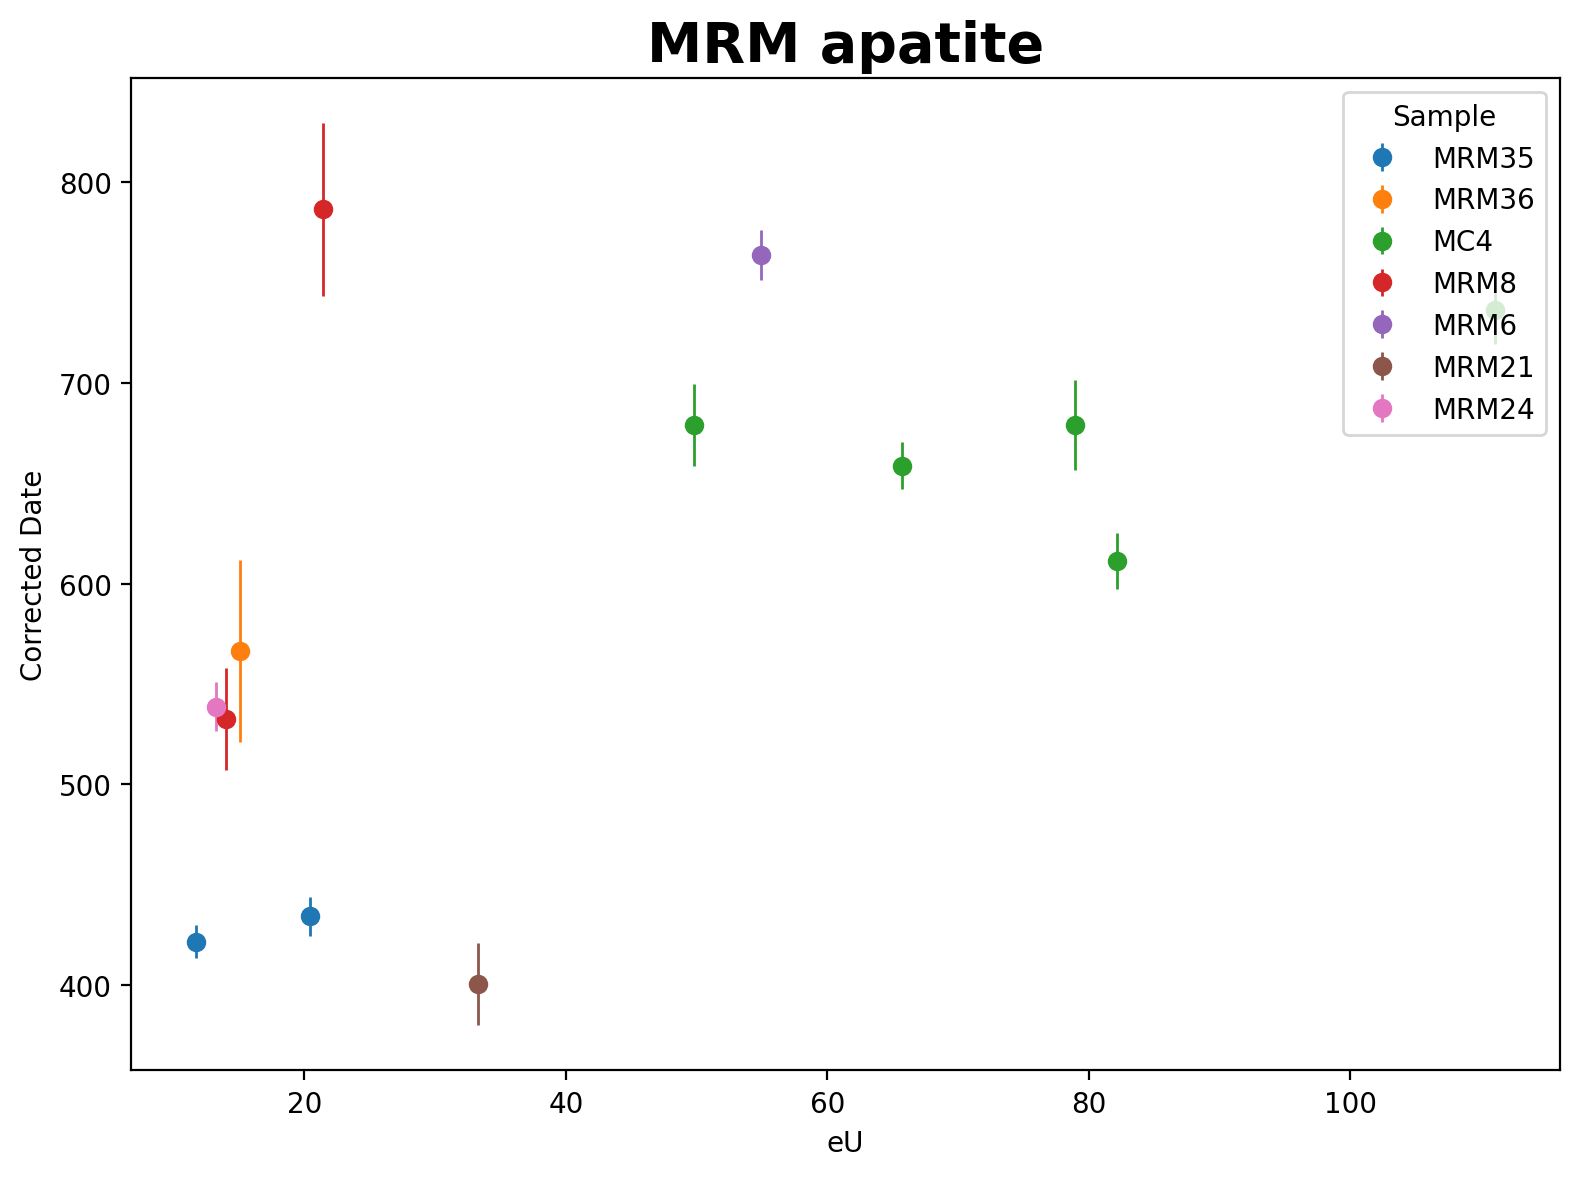

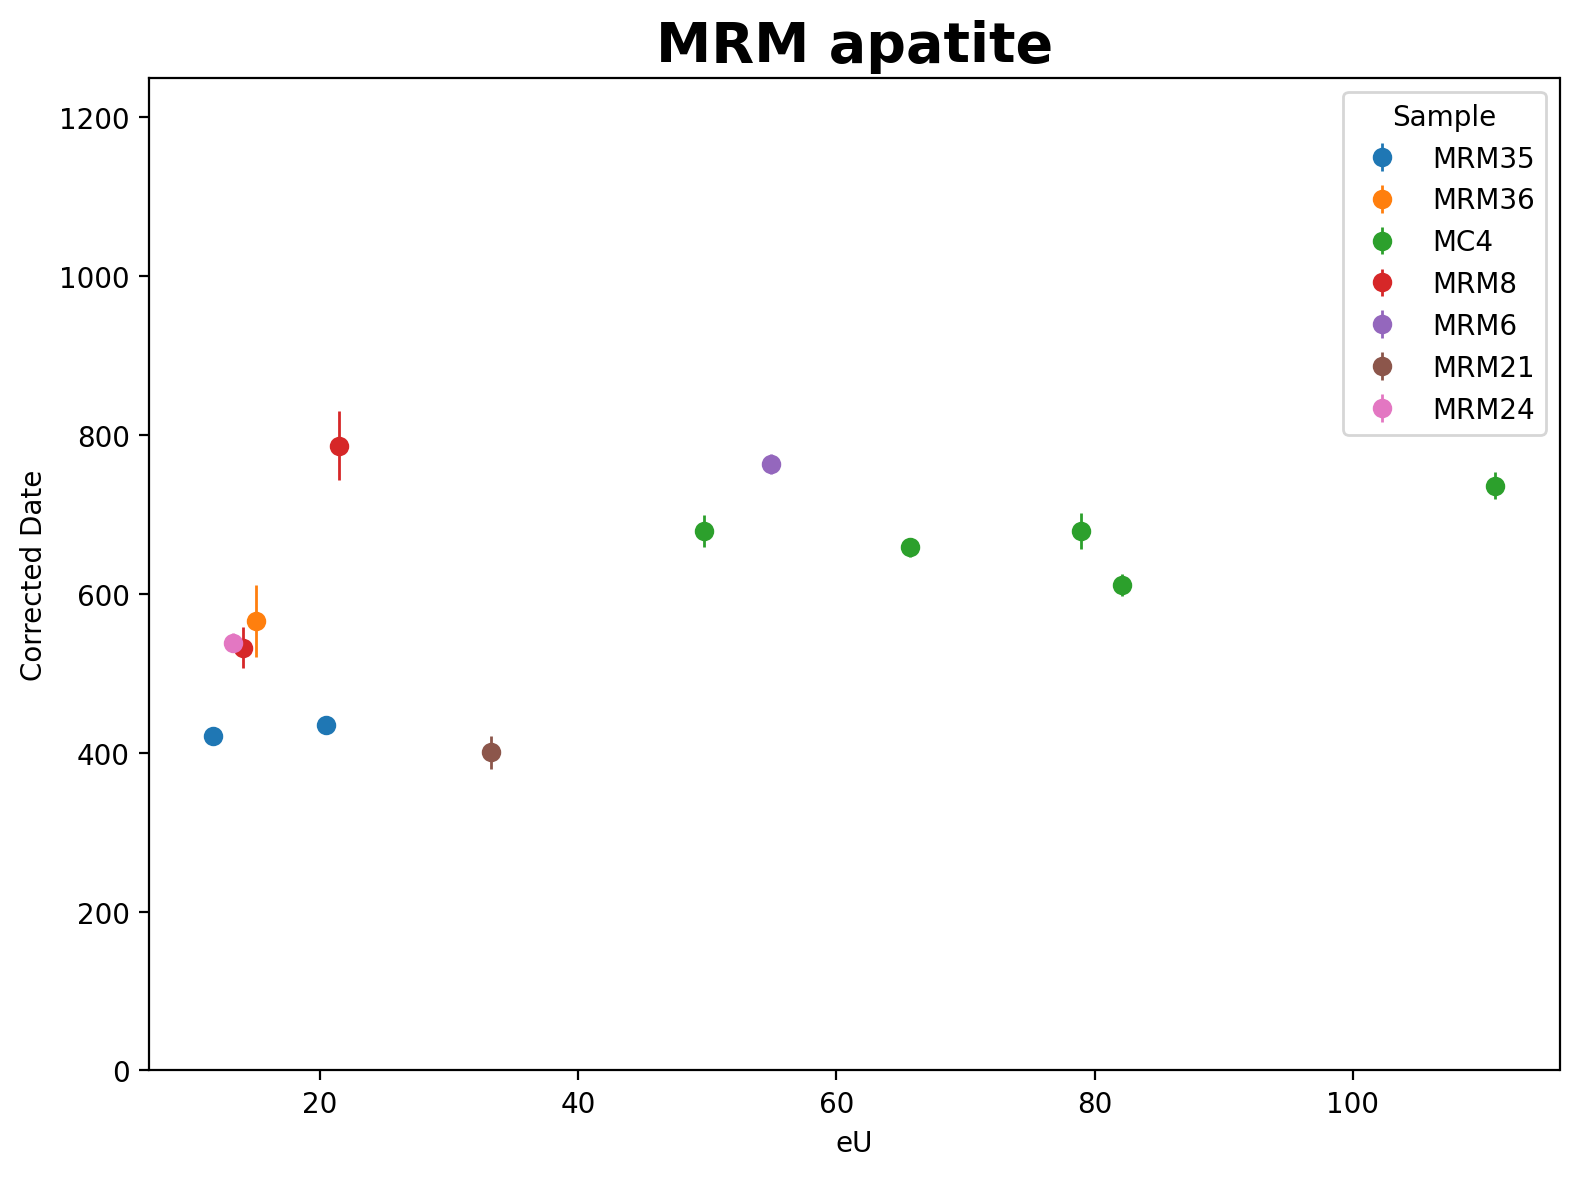

<Axes: title={'center': 'MRM apatite'}, xlabel='eU', ylabel='Corrected Date'>

In [15]:
plot_age_eU(MRM_apatite_data, 'MRM apatite')
plot_age_eU(MRM_apatite_data, 'MRM apatite', y_max = 1250)

In [16]:
high_eu_apatite_mean = MRM_apatite_data[MRM_apatite_data['eU'] > 40]['corrected_date'].mean()
print(round(high_eu_apatite_mean,2))

apatite_n = len(MRM_apatite_data[MRM_apatite_data['eU'] > 40])
high_eu_apatite_std_dev = MRM_apatite_data[MRM_apatite_data['eU'] > 40]['corrected_date'].std()
high_eu_apatite_sem = high_eu_apatite_std_dev / np.sqrt(apatite_n)
print(round(high_eu_apatite_sem,2))

688.05
22.32


In [17]:
high_eu_zircon_data = MRM_Archean_data[MRM_Archean_data['eU'] > 750]
high_eu_zircon_data_filtered = high_eu_zircon_data[high_eu_zircon_data['corrected_date'] < 500]
high_eu_zircon_mean = high_eu_zircon_data_filtered['corrected_date'].mean()
print(round(high_eu_zircon_mean,2))

zircon_n = len(high_eu_zircon_data_filtered['corrected_date'])
high_eu_zircon_std_dev = high_eu_zircon_data_filtered['corrected_date'].std()
high_eu_zircon_sem = high_eu_zircon_std_dev / np.sqrt(zircon_n)
print(round(high_eu_zircon_sem,2))

227.8
29.4


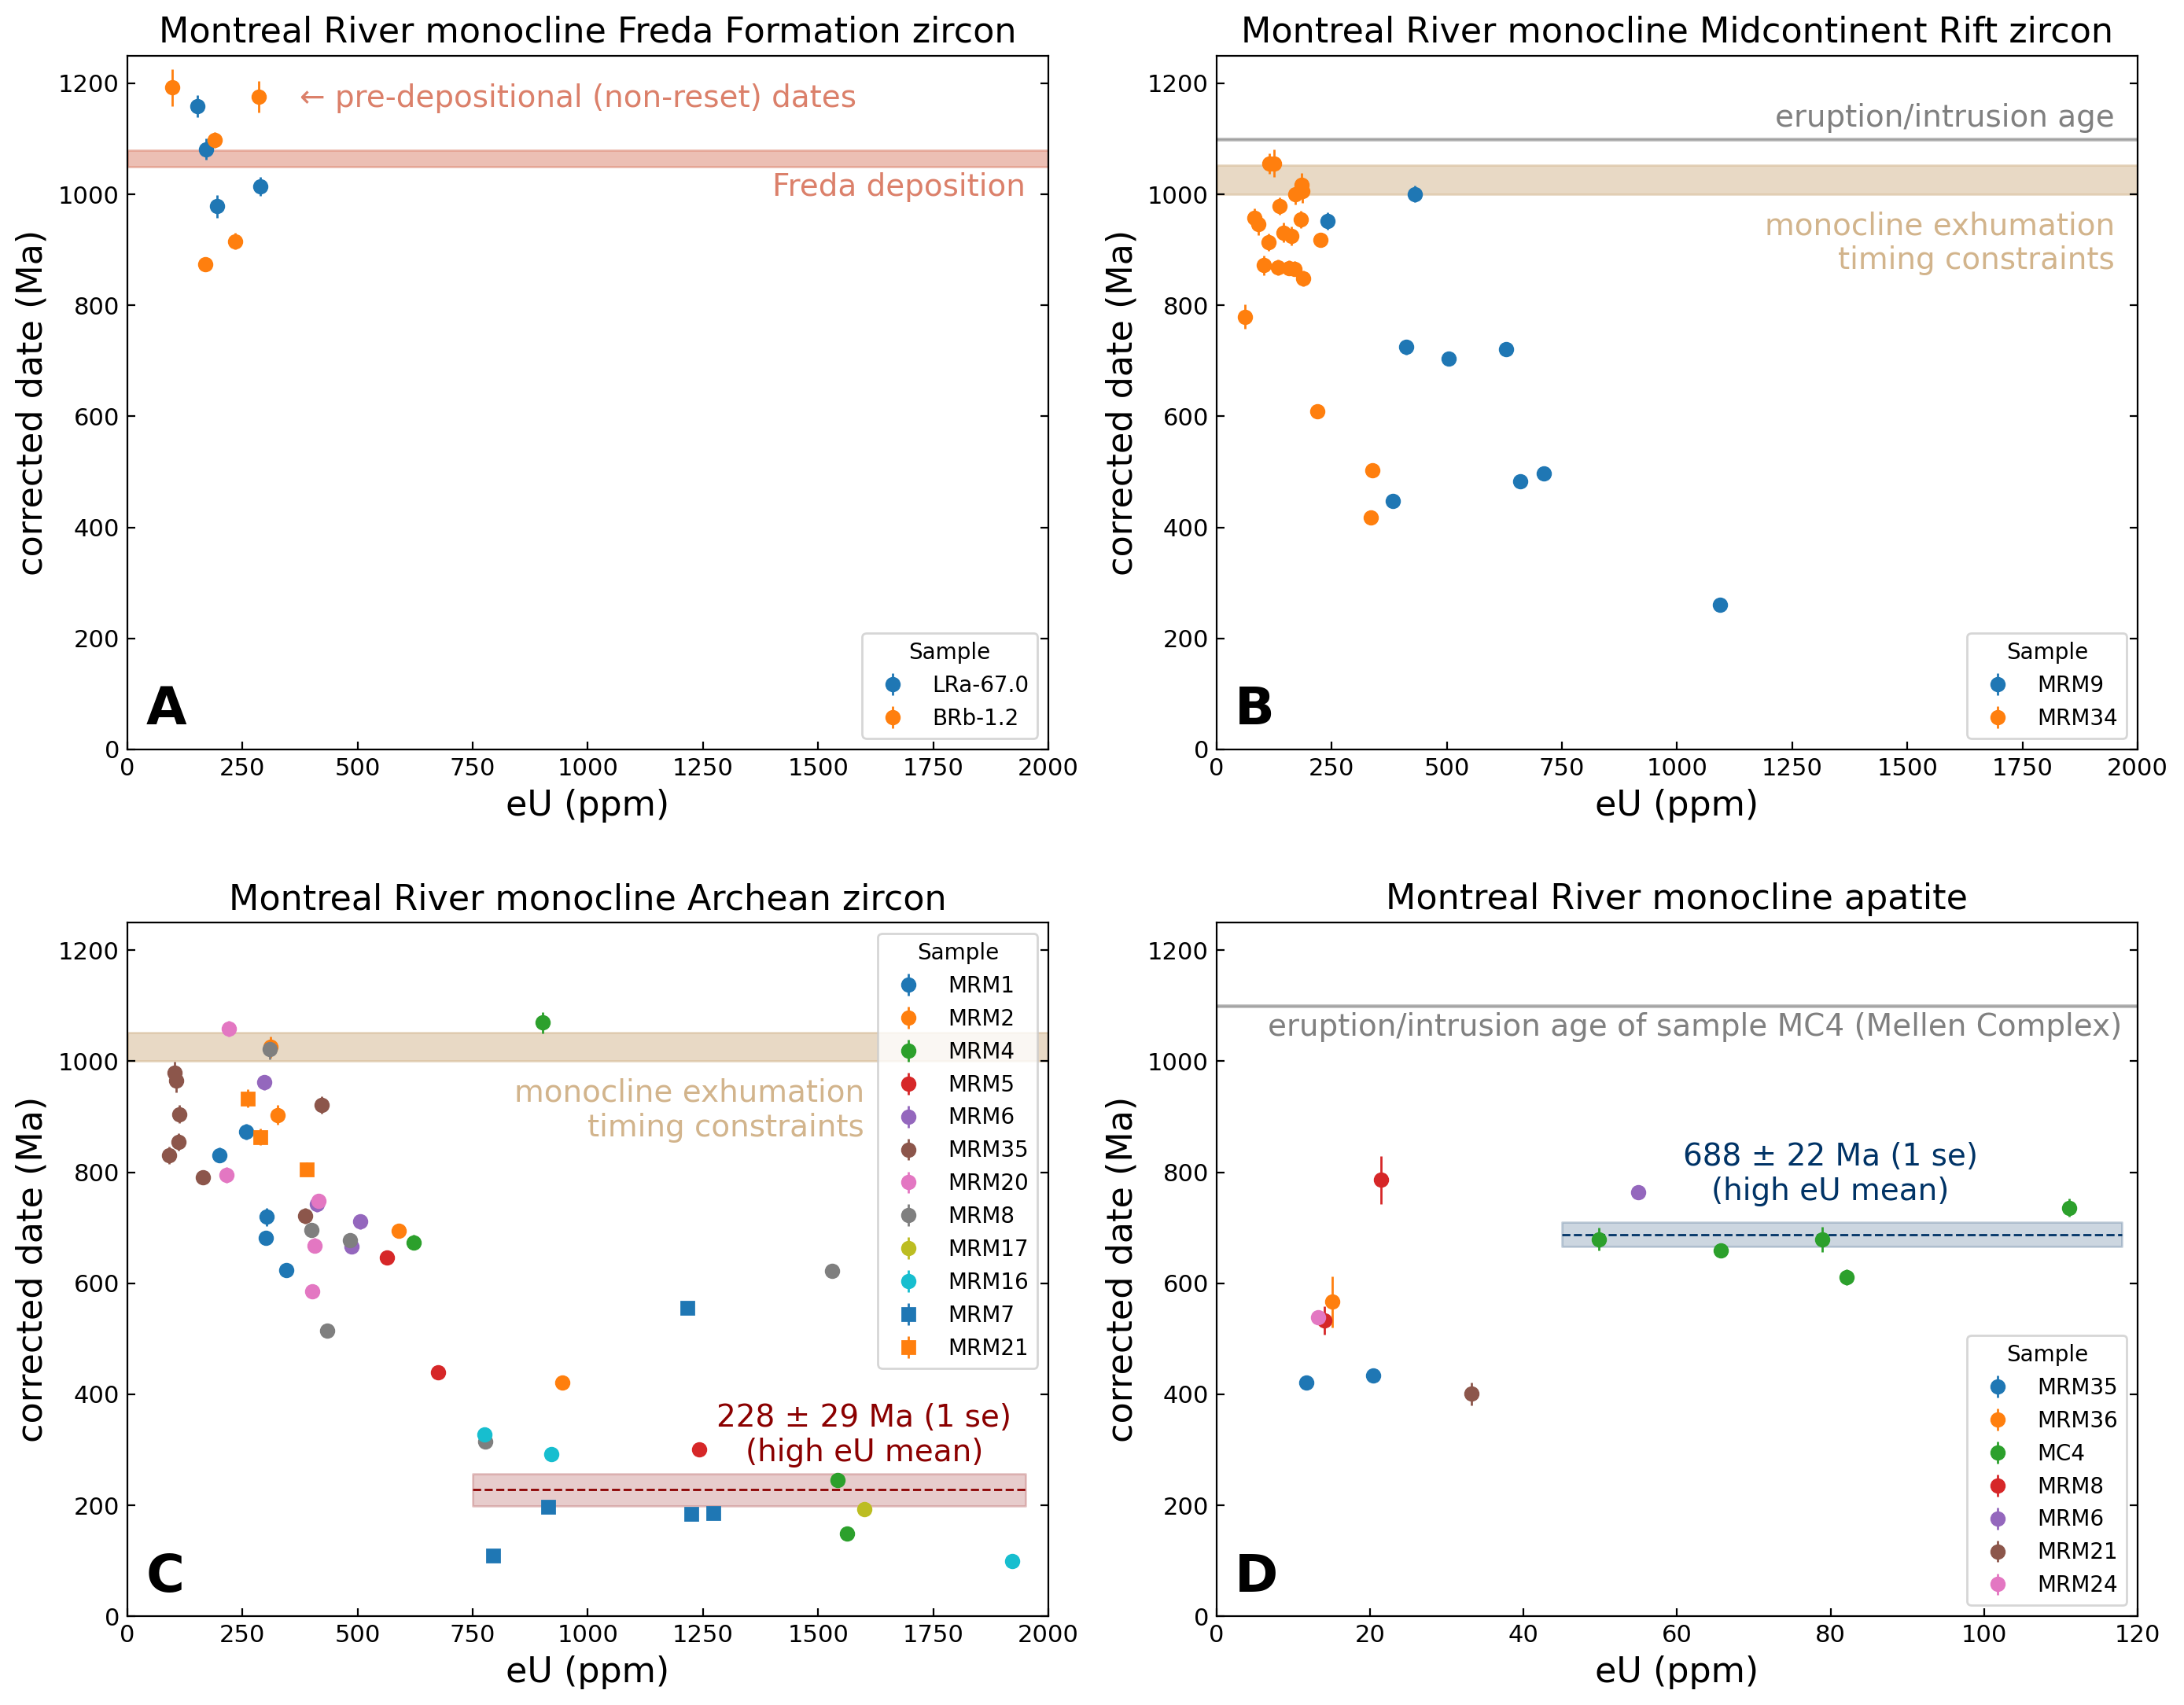

In [18]:
fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(14, 12))  # Adjust nrows and ncols as needed

plot_age_eU(MRM_Freda_data, 'Montreal River monocline Freda Formation zircon', x_max= 2000, y_max = 1250, ax=axs[0, 0],
            legend_loc='lower right')
axs[0, 0].fill_betweenx(y=[1050, 1080], x1=0, x2=2000, color='#db806a', alpha=.5)
axs[0, 0].text(1950, 1040, 'Freda deposition', fontsize=14, color='#db806a', 
               horizontalalignment='right', verticalalignment='top')
axs[0, 0].text(375, 1200, '← pre-depositional (non-reset) dates', fontsize=14, color='#db806a', 
               horizontalalignment='left', verticalalignment='top')

plot_age_eU(MRM_Archean_data, 'Montreal River monocline Archean zircon', x_max= 2000, y_max = 1250, ax=axs[1, 0])
axs[1, 0].fill_betweenx(y=[1000, 1052], x1=0, x2=2000, color='tan', alpha=.5)
axs[1, 0].text(1600, 970, 'monocline exhumation\ntiming constraints', fontsize=14, color='tan', 
               horizontalalignment='right', verticalalignment='top')
axs[1, 0].hlines(y=high_eu_zircon_mean, xmin=750, xmax=1950, color='#8B0000', linestyle='--', linewidth=1)
axs[1, 0].fill_betweenx(y=[high_eu_zircon_mean-high_eu_zircon_sem, high_eu_zircon_mean+high_eu_zircon_sem], 
                        x1=750, x2=1950, color='#8B0000', alpha=.2)
axs[1, 0].text(1600, high_eu_zircon_mean+40, 
               str(round(high_eu_zircon_mean))+ ' ± ' + str(round(high_eu_zircon_sem)) + ' Ma (1 se)\n(high eU mean)',  
               fontsize=14, color='#8B0000', horizontalalignment='center', verticalalignment='bottom')

plot_age_eU(MRM_rift_data, 'Montreal River monocline Midcontinent Rift zircon', x_max= 2000, y_max = 1250, ax=axs[0, 1],
            legend_loc='lower right')
axs[0, 1].fill_betweenx(y=[1098, 1101], x1=0, x2=2000, color='grey', alpha=.5)
axs[0, 1].text(1950, 1110, 'eruption/intrusion age', fontsize=14, color='grey', 
               horizontalalignment='right', verticalalignment='bottom')
axs[0, 1].fill_betweenx(y=[1000, 1052], x1=0, x2=2000, color='tan', alpha=.5)
axs[0, 1].text(1950, 970, 'monocline exhumation\ntiming constraints', fontsize=14, color='tan', 
               horizontalalignment='right', verticalalignment='top')

plot_age_eU(MRM_apatite_data, 'Montreal River monocline apatite', x_max= 120, y_max = 1250, ax=axs[1, 1], legend_loc='lower right')
axs[1, 1].fill_betweenx(y=[1098, 1101], x1=0, x2=120, color='grey', alpha=.5)
axs[1, 1].text(118, 1088, 'eruption/intrusion age of sample MC4 (Mellen Complex)', fontsize=14, color='grey', horizontalalignment='right', verticalalignment='top')
axs[1, 1].hlines(y=high_eu_apatite_mean, xmin=45, xmax=118, color='#003366', linestyle='--', linewidth=1)
axs[1, 1].fill_betweenx(y=[high_eu_apatite_mean-high_eu_apatite_sem, high_eu_apatite_mean+high_eu_apatite_sem], 
                        x1=45, x2=118, color='#003366', alpha=.2)
axs[1, 1].text(80, high_eu_apatite_mean+50, 
               str(round(high_eu_apatite_mean))+ ' ± ' + str(round(high_eu_apatite_sem)) + ' Ma (1 se)\n(high eU mean)', 
               fontsize=14, color='#003366', horizontalalignment='center', verticalalignment='bottom')

for ax in axs.flat:
    ax.set_xlabel("eU (ppm)", fontsize=16)
    ax.set_ylabel("corrected date (Ma)", fontsize=16)
    ax.set_title(ax.get_title(), fontsize=16)
    ax.tick_params(axis='both', which='major', labelsize=11, direction='in') 
    ax.tick_params(axis='y', which='both', left=True, right=True)

axs[0, 0].text(0.02, 0.02, 'A', transform=axs[0, 0].transAxes, fontsize=24, fontweight='bold', va='bottom')
axs[0, 1].text(0.02, 0.02, 'B', transform=axs[0, 1].transAxes, fontsize=24, fontweight='bold', va='bottom')
axs[1, 0].text(0.02, 0.02, 'C', transform=axs[1, 0].transAxes, fontsize=24, fontweight='bold', va='bottom')
axs[1, 1].text(0.02, 0.02, 'D', transform=axs[1, 1].transAxes, fontsize=24, fontweight='bold', va='bottom')

plt.subplots_adjust(hspace=5)
plt.tight_layout()
plt.savefig('../figures/age_eU_plots.pdf',bbox_inches='tight')
plt.show()